# 01 — Khám phá dữ liệu Bank Marketing
Hoàn thiện Mốc 1 trong docs/project_plan.md. Thời điểm dự đoán giả định: **đã lập lịch, chưa gọi**.

Khám phá quan hệ biến–nhãn **chỉ trên train**. Validation/test chỉ được kiểm tra chất lượng và phân bố tổng. Baseline đã từng chấm test trước EDA, nên test không còn hoàn toàn chưa được xem. Notebook không fit mô hình, chọn biến, ngưỡng hoặc siêu tham số.

Nguồn: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), Moro, Rita & Cortez (2014), [DOI](https://doi.org/10.24432/C5K306), CC BY 4.0.
Dùng bank-additional-full.csv (41.188 dòng, 20 biến đầu vào), không nhầm với bank-full.csv.
Ý nghĩa biến được đối chiếu với bank-additional-names.txt trong [gói UCI chính thức](https://archive.ics.uci.edu/static/public/222/bank+marketing.zip).

UCI mô tả thứ tự dòng theo thời gian từ 05/2008 đến 11/2010. Không có ngày đầy đủ/customer ID: vị trí dòng là thứ tự tương đối, không khôi phục được chính xác ngày/năm hoặc danh tính khách hàng.


## 1. Môi trường và dữ liệu
Chọn Python của .venv để chạy notebook. Có thể chạy từ thư mục dự án bằng hai lệnh:

    .\.venv\Scripts\python.exe -m pip install -e ".[eda]"
    .\.venv\Scripts\python.exe tools/run_eda.py

Notebook dùng config và hàm chia tập của pipeline. Bảng/ảnh xuất vào reports/eda/, kết luận vào docs/eda_findings.md. CSV gốc và mô hình giữ nguyên.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/default.json").is_file()
            and (p / "src/subscription_prediction").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from subscription_prediction.data import read_config, load_data, split_data
from subscription_prediction.eda import (
    column_profile, split_profile, category_rates, ordered_blocks, categorical_shift,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)

config = read_config(ROOT / "configs/default.json")
if config["split_strategy"] != "temporal":
    raise ValueError("Notebook này cần split_strategy=temporal.")
raw = pd.read_csv(config["data_path"], sep=config["separator"])
X, y = load_data(config)
splits = split_data(X, y, config)
X_train, y_train = splits["train"]
train_raw = raw.loc[X_train.index].copy()
if "duration" in X:
    raise ValueError("Cần loại duration trong config trước khi phân tích.")

OUTPUT = ROOT / "reports/eda"
OUTPUT.mkdir(parents=True, exist_ok=True)
def save_table(table, name):
    table.to_csv(OUTPUT / f"{name}.csv", encoding="utf-8", index=True)
    return table
def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

data_hash = hashlib.sha256(config["data_path"].read_bytes()).hexdigest()
versions = {p: importlib.metadata.version(p)
            for p in ["pandas", "numpy", "scikit-learn", "matplotlib", "nbclient"]}
print(f"Dữ liệu: {raw.shape[0]:,} dòng x {raw.shape[1]} cột; {X.shape[1]} biến mô hình")
print("SHA-256:", data_hash)
display(pd.Series(versions, name="version").to_frame())


Dữ liệu: 41,188 dòng x 21 cột; 19 biến mô hình
SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8


,version
pandas,2.3.3
numpy,2.5.3
scikit-learn,1.9.1
matplotlib,3.11.2
nbclient,0.11.0


## 2. Chất lượng dữ liệu và nhãn trên train
**unknown** là chuỗi chỉ thông tin không biết, khác NaN. Không tự xóa bản ghi trùng: thiếu customer ID nên không biết đó là lỗi ghi dữ liệu hay các liên hệ thực tế có cùng thuộc tính.


,dtype,unique_count,missing_count,unknown_count,missing_pct,unknown_pct
column,,,,,,
age,int64,63,0,0,0.0,0.000000
job,object,12,0,249,0.0,0.863654
marital,object,4,0,49,0.0,0.169956
education,object,8,0,1183,0.0,4.103222
default,object,3,0,7302,0.0,25.326905
housing,object,3,0,694,0.0,2.407131
loan,object,3,0,694,0.0,2.407131
contact,object,2,0,0,0.0,0.000000
month,object,9,0,0,0.0,0.000000


,value
full_rows,41188
full_columns_including_y,21
full_missing_cells,0
full_duplicate_rows_after_first,12
train_duplicate_full_rows_after_first,9
train_duplicate_model_inputs_after_first,1589


,unknown_count,unknown_pct
column,,
default,7302,25.326905
education,1183,4.103222
housing,694,2.407131
loan,694,2.407131
job,249,0.863654
marital,49,0.169956


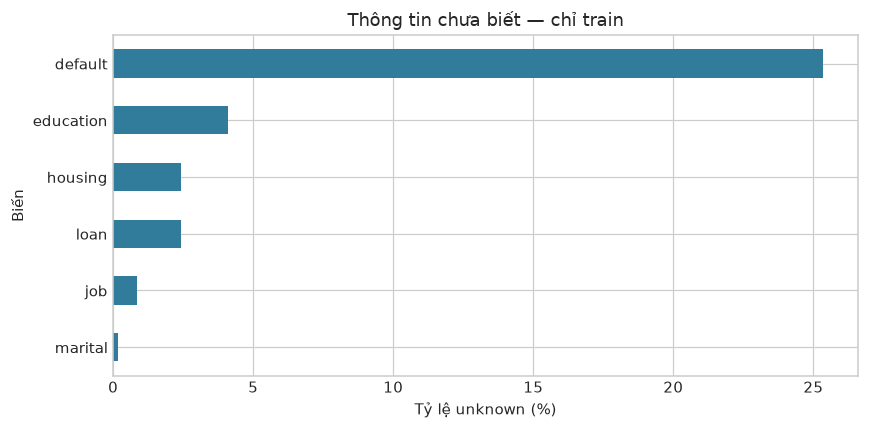

In [2]:
schema = save_table(column_profile(train_raw), "train_column_profile")
display(schema)
quality = pd.Series({
    "full_rows": len(raw), "full_columns_including_y": raw.shape[1],
    "full_missing_cells": int(raw.isna().sum().sum()),
    "full_duplicate_rows_after_first": int(raw.duplicated().sum()),
    "train_duplicate_full_rows_after_first": int(train_raw.duplicated().sum()),
    "train_duplicate_model_inputs_after_first": int(X_train.duplicated().sum()),
}, name="value")
display(save_table(quality.to_frame(), "quality_summary"))
unknown = schema.loc[schema.unknown_count > 0, ["unknown_count", "unknown_pct"]].sort_values(
    "unknown_pct", ascending=False)
display(unknown)
fig, ax = plt.subplots(figsize=(8, 4))
unknown.unknown_pct.sort_values().plot.barh(ax=ax, color="#307c9a")
ax.set(xlabel="Tỷ lệ unknown (%)", ylabel="Biến", title="Thông tin chưa biết — chỉ train")
show_figure(fig, "01_train_unknown")


In [3]:
labels = y_train.value_counts().reindex([0, 1], fill_value=0).to_frame("rows")
labels.index = pd.Index(["no", "yes"], name="label")
labels["pct"] = 100 * labels.rows / len(y_train)
display(save_table(labels, "train_labels"))
print(f"Luôn đoán no đạt accuracy train: {1-y_train.mean():.2%}, nhưng bỏ sót toàn bộ yes.")


,rows,pct
label,,
no,27225,94.429607
yes,1606,5.570393


Luôn đoán no đạt accuracy train: 94.43%, nhưng bỏ sót toàn bộ yes.


Mất cân bằng nhãn khiến accuracy dễ gây hiểu nhầm. Đánh giá mô hình ở bước sau cần average precision, precision/recall và lift theo ngân sách. Giữ cách xử lý unknown của baseline; các cách imputation khác phải được thử có kiểm soát.


## 3. Tuổi và lịch sử chiến dịch — chỉ train
**pdays=999** là trạng thái chưa được liên hệ ở chiến dịch trước, không phải 999 ngày.
Biểu đồ số ngày chỉ vẽ các dòng khác 999. previous là số liên hệ ở chiến dịch trước; không trực tiếp mô tả chiến dịch hiện tại.


,count,mean,std,min,1%,25%,50%,75%,99%,max
age,28831.0,40.177483,9.335439,18.000,24.000,33.000,39.000,47.000,59.000,95.000
campaign,28831.0,2.768270,3.111751,1.000,1.000,1.000,2.000,3.000,17.000,56.000
pdays,28831.0,997.172592,42.583054,0.000,999.000,999.000,999.000,999.000,999.000,999.000
previous,28831.0,0.035899,0.192456,0.000,0.000,0.000,0.000,0.000,1.000,3.000
emp.var.rate,28831.0,1.000409,0.747091,-1.800,-1.800,1.100,1.400,1.400,1.400,1.400
cons.price.idx,28831.0,93.810004,0.416240,92.756,92.843,93.444,93.918,93.994,94.465,94.465
cons.conf.idx,28831.0,-39.792935,3.369460,-50.000,-47.100,-42.700,-41.800,-36.400,-36.100,-36.100
euribor3m,28831.0,4.685469,0.704179,1.410,1.415,4.857,4.957,4.962,4.968,5.045
nr.employed,28831.0,5208.861153,28.165318,5099.100,5099.100,5191.000,5228.100,5228.100,5228.100,5228.100


,rows,pct
pdays=999,28778,99.816170
pdays!=999,53,0.183830
previous=0,27829,96.524574
previous>0,1002,3.475426


,pdays_without_999
count,53.000000
mean,4.924528
std,2.525631
min,0.000000
25%,3.000000
50%,5.000000
75%,6.000000
max,11.000000


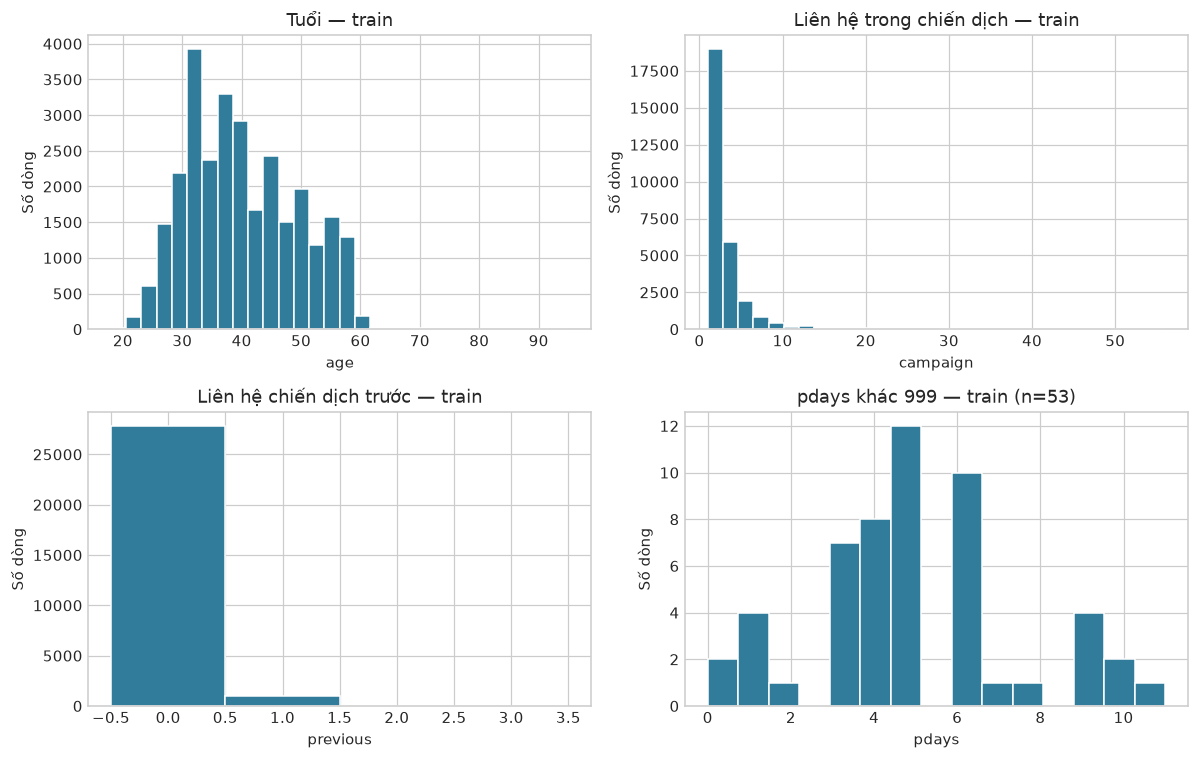

In [4]:
display(save_table(X_train.select_dtypes(include="number").describe(
    percentiles=[.01, .25, .5, .75, .99]).T, "train_numeric_summary"))
contacted_before = X_train.pdays.ne(999)
history = pd.DataFrame({"rows": [
    int((~contacted_before).sum()), int(contacted_before.sum()),
    int(X_train.previous.eq(0).sum()), int(X_train.previous.gt(0).sum()),
]}, index=["pdays=999", "pdays!=999", "previous=0", "previous>0"])
history["pct"] = 100 * history.rows / len(X_train)
display(save_table(history, "train_history"))
display(X_train.loc[contacted_before, "pdays"].describe().to_frame("pdays_without_999"))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, series, title, bins in [
    (axes[0, 0], X_train.age, "Tuổi — train", 30),
    (axes[0, 1], X_train.campaign, "Liên hệ trong chiến dịch — train", 30),
    (axes[1, 0], X_train.previous, "Liên hệ chiến dịch trước — train",
     np.arange(-.5, X_train.previous.max()+1.5)),
    (axes[1, 1], X_train.loc[contacted_before, "pdays"],
     f"pdays khác 999 — train (n={contacted_before.sum():,})", 15),
]:
    ax.hist(series, bins=bins, color="#307c9a", edgecolor="white")
    ax.set(title=title, ylabel="Số dòng", xlabel=series.name)
show_figure(fig, "02_train_numeric_distributions")


## 4. Nghề nghiệp, học vấn và kết quả chiến dịch trước — chỉ train
Đọc tỷ lệ yes cùng số mẫu. Nhóm nhỏ có thể dao động mạnh; các quan hệ này không chứng minh nhân quả hoặc hiệu quả khi triển khai.


**job**

,rows,yes_count,yes_pct
category,,,
admin.,7107,416,5.853384
blue-collar,6705,337,5.026100
technician,5054,271,5.362089
services,2826,143,5.060156
management,2096,127,6.059160
entrepreneur,1105,60,5.429864
self-employed,1043,62,5.944391
retired,879,81,9.215017
housemaid,838,30,3.579952


**education**

,rows,yes_count,yes_pct
category,,,
university.degree,8345,533,6.387058
high.school,6459,356,5.511689
basic.9y,4329,231,5.336105
professional.course,3795,199,5.243742
basic.4y,3051,136,4.457555
basic.6y,1655,89,5.377644
unknown,1183,60,5.071851
illiterate,14,2,14.285714


**poutcome**

,rows,yes_count,yes_pct
category,,,
nonexistent,27829,1543,5.544576
failure,952,56,5.882353
success,50,7,14.000000


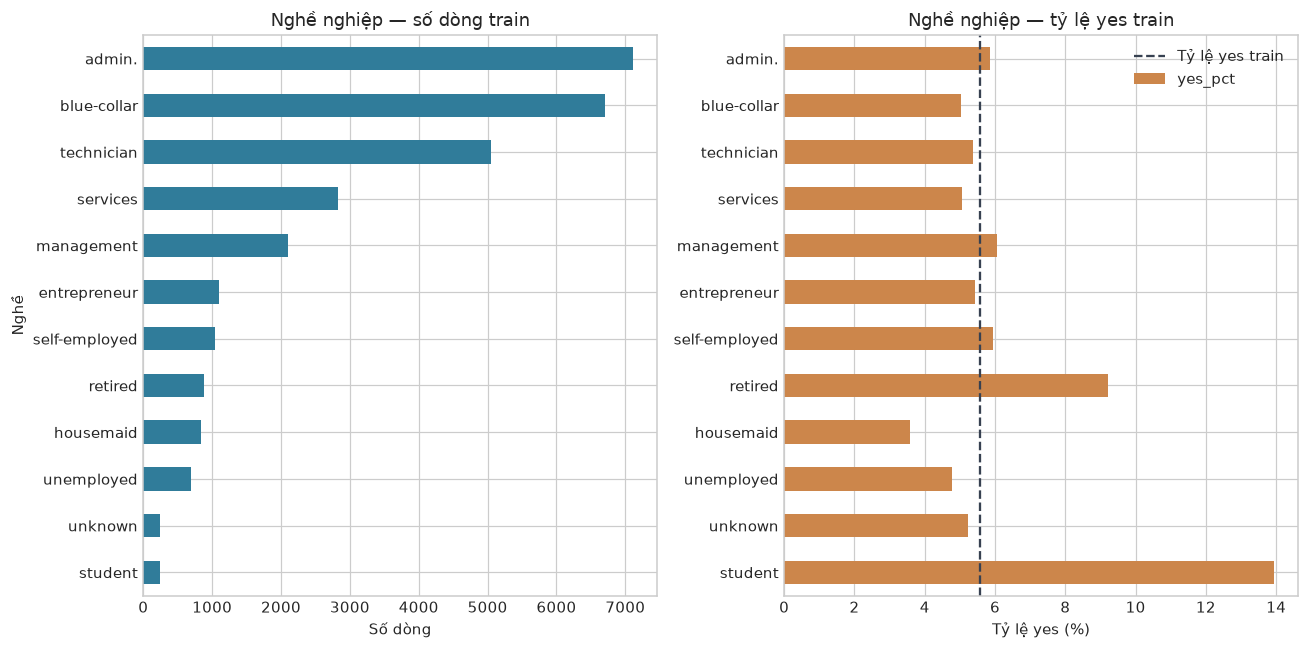

In [5]:
group_tables = {}
for column in ["job", "education", "poutcome"]:
    table = save_table(category_rates(X_train[column], y_train), f"train_rates_{column}")
    group_tables[column] = table
    display(Markdown(f"**{column}**"))
    display(table)
jobs = group_tables["job"].sort_values("rows")
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
jobs.rows.plot.barh(ax=axes[0], color="#307c9a")
jobs.yes_pct.plot.barh(ax=axes[1], color="#cc864b", legend=False)
axes[0].set(title="Nghề nghiệp — số dòng train", xlabel="Số dòng", ylabel="Nghề")
axes[1].set(title="Nghề nghiệp — tỷ lệ yes train", xlabel="Tỷ lệ yes (%)", ylabel="")
axes[1].axvline(100*y_train.mean(), color="#374151", linestyle="--", label="Tỷ lệ yes train")
axes[1].legend(loc="upper right")
show_figure(fig, "03_train_job_counts_and_rates")


## 5. Thay đổi theo thứ tự dòng bên trong train
10 khối liên tiếp có kích thước gần bằng nhau, **không phải tháng/năm**.
Không gộp tháng trùng tên của nhiều năm rồi coi đó là chuỗi thời gian đầy đủ.


,first_source_row,last_source_row,rows,yes_pct,age_median,campaign_median,euribor3m_median,nr_employed_median,pdays_999_pct
block,,,,,,,,,
1,0,2883,2884,2.427184,40.0,2.0,4.856,5191.0,100.000000
2,2884,5766,2883,3.468609,39.0,2.0,4.858,5191.0,100.000000
3,5767,8649,2883,3.954214,38.0,2.0,4.860,5191.0,100.000000
4,8650,11532,2883,4.058273,39.0,2.0,4.961,5228.1,100.000000
5,11533,14415,2883,5.306972,36.0,2.0,4.962,5228.1,100.000000
6,14416,17298,2883,7.110649,36.0,2.0,4.961,5228.1,100.000000
7,17299,20181,2883,5.688519,42.0,2.0,4.966,5228.1,100.000000
8,20182,23064,2883,5.515088,38.0,2.0,4.964,5228.1,100.000000
9,23065,25947,2883,5.445716,40.0,1.0,4.191,5195.8,99.340964


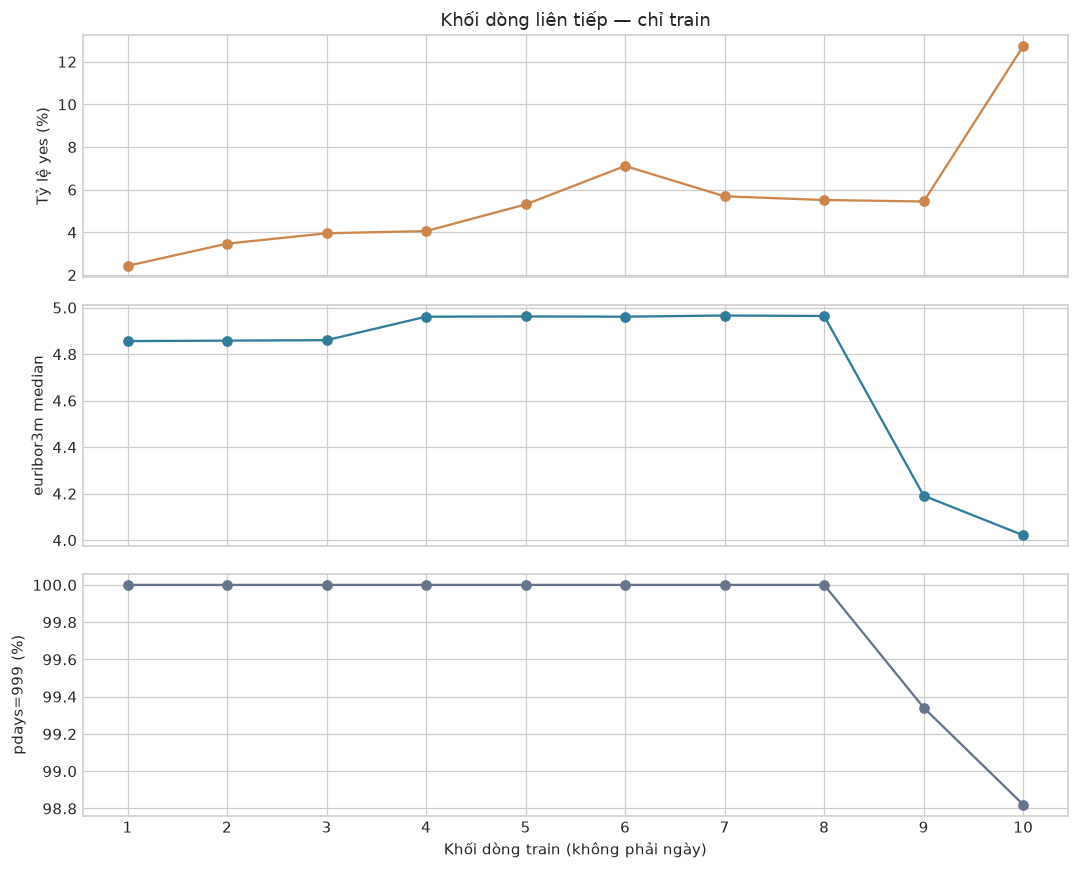

In [6]:
blocks = save_table(ordered_blocks(X_train, y_train), "train_ordered_blocks")
display(blocks)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(blocks.index, blocks.yes_pct, marker="o", color="#cc864b")
axes[0].set(ylabel="Tỷ lệ yes (%)", title="Khối dòng liên tiếp — chỉ train")
axes[1].plot(blocks.index, blocks.euribor3m_median, marker="o", color="#307c9a")
axes[1].set(ylabel="euribor3m median")
axes[2].plot(blocks.index, blocks.pdays_999_pct, marker="o", color="#64748b")
axes[2].set(ylabel="pdays=999 (%)", xlabel="Khối dòng train (không phải ngày)")
axes[2].set_xticks(blocks.index)
show_figure(fig, "04_train_ordered_blocks")


## 6. Chia tập và thay đổi phân bố tổng quát
Chỉ mô tả tỷ lệ nhãn tổng và đầu vào mỗi tập. Không phân tích nhóm sai/tương quan biến–nhãn trên test.
Tổng biến thiên (total variation) của biến phân loại nằm trong [0,1]: 0 là cùng phân bố.
Đây là số đo mô tả, không chứng minh nguyên nhân thay đổi.


,rows,first_source_row,last_source_row,yes_count,yes_pct,missing_cells,duplicate_full_rows,pdays_999_pct,previous_zero_pct
split,,,,,,,,,
train,28831,0,28830,1606,5.570393,0,9,99.816170,96.524574
validation,6178,28831,35008,658,10.650696,0,1,97.442538,68.274522
test,6179,35009,41187,2376,38.452824,0,2,78.896262,56.902411


,distinct_identical_full_rows
pair,
train/validation,0
train/test,0
validation/test,0


Không có customer ID để xác định/chia nhóm theo cùng khách hàng.


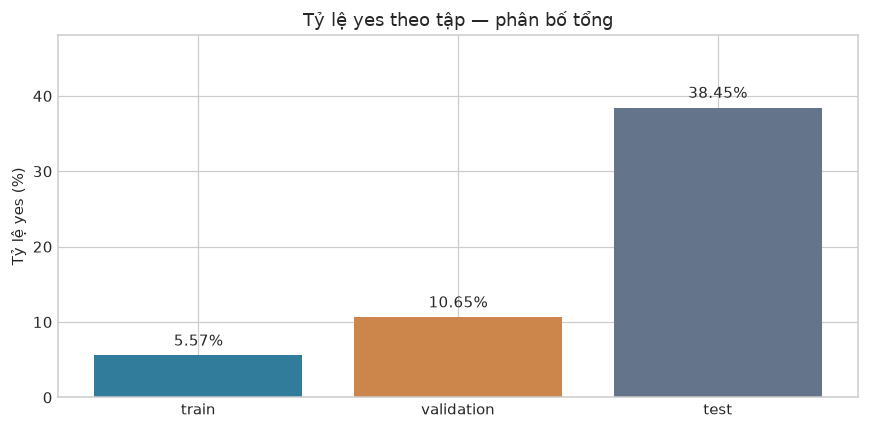

In [7]:
audit = save_table(split_profile(raw, splits), "split_audit")
display(audit)
assert sum(len(v[1]) for v in splits.values()) == len(raw)
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert set(splits[left][0].index).isdisjoint(splits[right][0].index)
assert audit.loc["train", "last_source_row"] < audit.loc["validation", "first_source_row"]
assert audit.loc["validation", "last_source_row"] < audit.loc["test", "first_source_row"]
overlaps = []
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    first = raw.loc[splits[left][0].index].drop_duplicates()
    second = raw.loc[splits[right][0].index].drop_duplicates()
    overlaps.append({"pair": f"{left}/{right}",
                     "distinct_identical_full_rows": len(first.merge(
                         second, on=list(raw.columns), how="inner"))})
display(save_table(pd.DataFrame(overlaps).set_index("pair"), "cross_split_duplicate_rows"))
print("Không có customer ID để xác định/chia nhóm theo cùng khách hàng.")
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(audit.index, audit.yes_pct, color=["#307c9a", "#cc864b", "#64748b"])
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in audit.yes_pct], padding=4)
ax.set(title="Tỷ lệ yes theo tập — phân bố tổng", ylabel="Tỷ lệ yes (%)")
ax.set_ylim(0, min(100, audit.yes_pct.max()*1.25))
show_figure(fig, "05_split_label_rates")


,train,validation,test
age,39.000,36.000,37.000
campaign,2.000,2.000,1.000
emp.var.rate,1.400,-1.800,-1.800
cons.price.idx,93.918,92.893,92.893
cons.conf.idx,-41.800,-46.200,-38.300
euribor3m,4.957,1.327,0.881
nr.employed,5228.100,5099.100,5017.500


,column,split,total_variation,unseen_category_pct
14,month,validation,0.700947,0.000000
12,contact,validation,0.401523,0.000000
19,poutcome,test,0.396222,0.000000
13,contact,test,0.352822,0.000000
18,poutcome,validation,0.282501,0.000000
15,month,test,0.256778,9.224794
1,job,test,0.240329,0.000000
7,default,test,0.216312,0.000000
0,job,validation,0.135947,0.000000
3,marital,test,0.134450,0.000000


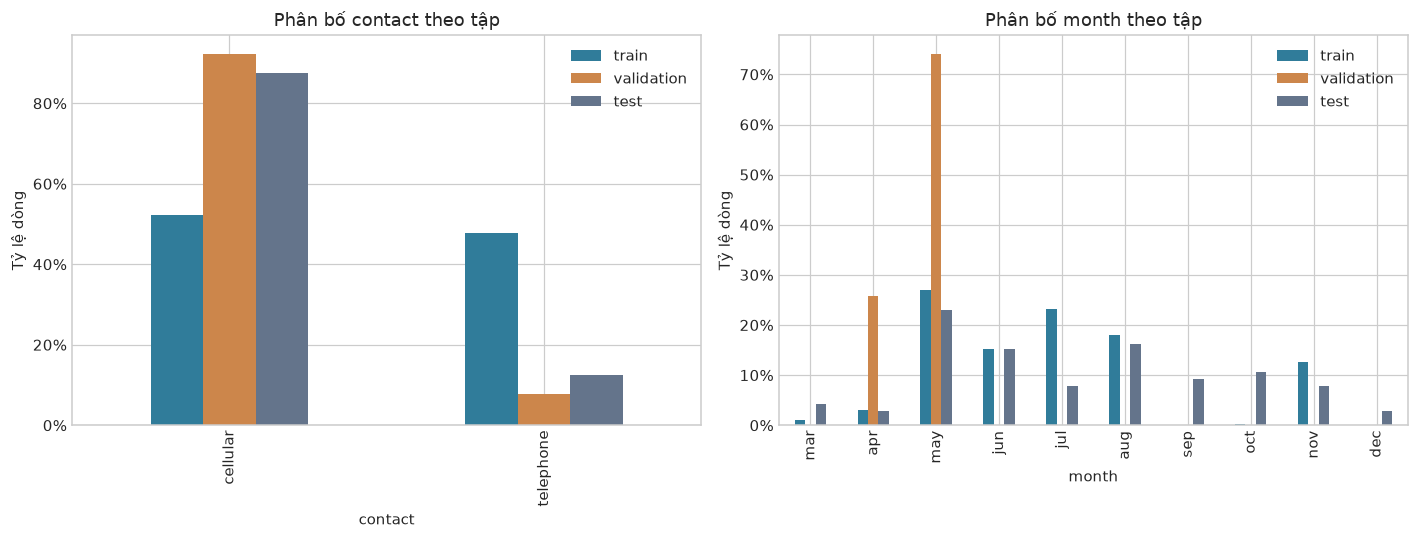

In [8]:
median_columns = ["age", "campaign", "emp.var.rate", "cons.price.idx",
                  "cons.conf.idx", "euribor3m", "nr.employed"]
medians = pd.DataFrame({name: features[median_columns].median()
                        for name, (features, _) in splits.items()})
display(save_table(medians, "feature_medians_by_split"))
shift = save_table(categorical_shift(splits), "categorical_shift")
display(shift)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for column, ax in zip(["contact", "month"], axes):
    proportions = pd.DataFrame({
        name: features[column].value_counts(normalize=True)
        for name, (features, _) in splits.items()
    }).fillna(0)
    if column == "month":
        order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
        proportions = proportions.reindex([m for m in order if m in proportions.index])
    save_table(proportions, f"{column}_distribution_by_split")
    proportions.plot.bar(ax=ax, color=["#307c9a", "#cc864b", "#64748b"])
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f"Phân bố {column} theo tập", ylabel="Tỷ lệ dòng", xlabel=column)
show_figure(fig, "06_feature_distribution_shift")


Khác biệt nhãn/đầu vào mô tả thay đổi theo giai đoạn. Chưa đủ phân biệt label shift, concept drift hoặc thay đổi cách chọn khách hàng.
Average precision phụ thuộc tỷ lệ yes nền: AP test cao hơn validation chưa chứng minh mô hình tốt hơn.
Thử nghiệm tiếp theo vẫn giữ thứ tự thời gian.


## 7. Biến có sẵn trước cuộc gọi
Các điều kiện dưới đây là đánh giá cho tình huống của dự án. File lịch sử không chứng minh rằng các biến đã được ghi nhận đúng lúc chấm điểm.


In [9]:
availability = pd.DataFrame([
    ("age, job, marital, education, default, housing, loan", "Có điều kiện",
     "Hồ sơ khách hàng cập nhật trước cuộc gọi; unknown được ghi nhận riêng."),
    ("contact, month, day_of_week", "Có điều kiện",
     "Chỉ dùng khi đúng kênh và lịch sắp gọi đã biết trước chấm điểm; file mô tả lần liên hệ cuối."),
    ("duration", "Không", "Chỉ biết khi cuộc gọi kết thúc; đã loại khỏi baseline."),
    ("campaign", "Cần xác minh",
     "UCI tính cả lần liên hệ cuối. Chỉ dùng số thứ tự cuộc gọi sắp thực hiện, không dùng tổng liên hệ phát sinh về sau."),
    ("pdays, previous, poutcome", "Có điều kiện",
     "Lịch sử chiến dịch trước đóng băng lúc chấm điểm; pdays=999 là trạng thái chưa được liên hệ."),
    ("emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed", "Có điều kiện",
     "Giá trị đã công bố trước dự đoán; xem độ trễ công bố và các lần sửa số liệu."),
    ("y", "Không", "Nhãn kết quả để học/đánh giá, không phải đầu vào."),
], columns=["variables", "availability", "condition"]).set_index("variables")
display(save_table(availability, "feature_availability"))


,availability,condition
variables,,
"age, job, marital, education, default, housing, loan",Có điều kiện,Hồ sơ khách hàng cập nhật trước cuộc gọi; unknown được ghi nhận riêng.
"contact, month, day_of_week",Có điều kiện,Chỉ dùng khi đúng kênh và lịch sắp gọi đã biết trước chấm điểm; file mô tả lần liên hệ cuối.
duration,Không,Chỉ biết khi cuộc gọi kết thúc; đã loại khỏi baseline.
campaign,Cần xác minh,"UCI tính cả lần liên hệ cuối. Chỉ dùng số thứ tự cuộc gọi sắp thực hiện, không dùng tổng liên hệ phát sinh về sau."
"pdays, previous, poutcome",Có điều kiện,Lịch sử chiến dịch trước đóng băng lúc chấm điểm; pdays=999 là trạng thái chưa được liên hệ.
"emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed",Có điều kiện,Giá trị đã công bố trước dự đoán; xem độ trễ công bố và các lần sửa số liệu.
y,Không,"Nhãn kết quả để học/đánh giá, không phải đầu vào."


## 8. Kết luận và bước tiếp theo
Cell cuối sinh báo cáo từ số liệu thực tế, kèm hash dữ liệu và phiên bản thư viện để chạy lại.
Không thay đổi cấu hình, dữ liệu gốc hay mô hình.


In [10]:
split_lines = "\n".join(
    f"| {name} | {int(row['rows']):,} | {int(row['yes_count']):,} | {row['yes_pct']:.2f}% |"
    for name, row in audit.iterrows())
unknown_lines = "\n".join(
    f"- **{column}**: {int(row['unknown_count']):,} dòng ({row['unknown_pct']:.2f}%)."
    for column, row in unknown.iterrows())
shift_lines = "\n".join(
    f"- {r['column']} ({r['split']} so với train): total variation = {r['total_variation']:.3f}; "
    f"nhóm chưa có trong train = {r['unseen_category_pct']:.2f}%."
    for _, r in shift.head(4).iterrows())
largest_job = group_tables["job"].iloc[0]
report = f"""# Nhận xét EDA — Bank Marketing

Sinh từ notebooks/01_eda.ipynb và configs/default.json.
Khám phá quan hệ biến–nhãn trên train; validation/test chỉ kiểm tra chất lượng và phân bố tổng.
Baseline đã chấm test trước EDA, nên test không còn hoàn toàn chưa được xem.
Không chọn mô hình, biến, ngưỡng hoặc siêu tham số từ test trong báo cáo này.

## Dữ liệu và chất lượng

- File {config['data_path'].name}: {len(raw):,} dòng, {raw.shape[1]} cột gồm nhãn.
- Sau khi loại duration và nhãn y: {X.shape[1]} biến đầu vào.
- NaN toàn bộ file: {int(raw.isna().sum().sum()):,} ô.
- Dòng trùng đầy đủ sau lần đầu: {int(raw.duplicated().sum()):,} toàn bộ file; {int(train_raw.duplicated().sum()):,} train.
- Thiếu customer ID, không xác nhận được cùng người giữa các tập. Không tự xóa dòng trùng hoặc coi source_row là customer ID.

Các giá trị unknown trên train (khác NaN):

{unknown_lines}

Baseline hiện giữ unknown như nhóm phân loại. Các cách xử lý khác cần thử có kiểm soát.

## Mất cân bằng nhãn và thời gian

| Tập | Số dòng | Số yes | Tỷ lệ yes |
| --- | ---: | ---: | ---: |
{split_lines}

Luôn đoán no đạt accuracy train {1-y_train.mean():.2%}, nhưng bỏ sót toàn bộ yes.
Bên trong train, 10 khối dòng liên tiếp có tỷ lệ yes từ {blocks.yes_pct.min():.2f}% đến {blocks.yes_pct.max():.2f}%.
Các khối là vị trí dòng, không phải tháng/năm đầy đủ.

Các khác biệt phân loại lớn nhất đo được:

{shift_lines}

Tỷ lệ nhãn và phân bố đầu vào khác nhau giữa các giai đoạn. Đây là bằng chứng mô tả dịch chuyển phân bố,
chưa đủ phân biệt label shift, concept drift hoặc thay đổi cách chọn khách hàng.
Không kết luận AP test cao hơn validation là cải thiện: AP phụ thuộc tỷ lệ yes nền.
Đánh giá theo thời gian, average precision và lift so với baseline ngẫu nhiên cùng tập.

## Tuổi, nghề và lịch sử chiến dịch — train

- Tuổi: median {X_train.age.median():.0f}, khoảng {X_train.age.min():.0f}–{X_train.age.max():.0f}.
- Nghề nhiều nhất: {group_tables['job'].index[0]}, {int(largest_job['rows']):,} dòng.
- campaign: median {X_train.campaign.median():.0f}, tối đa {X_train.campaign.max():.0f}; có đuôi dài.
- pdays=999: {int((~contacted_before).sum()):,}/{len(X_train):,} dòng ({100*(~contacted_before).mean():.2f}%).
- Chỉ {int(contacted_before.sum()):,} dòng có pdays khác 999; không diễn giải 999 là số ngày hay dùng trung bình nguyên trạng như số ngày điển hình.
- previous=0: {int(X_train.previous.eq(0).sum()):,} dòng ({100*X_train.previous.eq(0).mean():.2f}%).

Quan hệ nhãn theo nghề, học vấn và kết quả chiến dịch trước chỉ khảo sát trên train.
Đọc cùng số mẫu; nhóm nhỏ có thể dao động mạnh. Không kết luận nhân quả từ các quan hệ này.

## Biến có sẵn trước cuộc gọi

Giả định đã lập lịch, chưa gọi. duration chỉ biết sau cuộc gọi và đã bị loại.
campaign trong UCI tính cả lần liên hệ cuối: cần xác minh nó là số thứ tự cuộc gọi sắp thực hiện,
không phải tổng số liên hệ phát sinh về sau.
contact/month/day_of_week chỉ dùng khi khớp lịch/kênh dự kiến đã biết trước chấm điểm.
pdays/previous/poutcome cần lịch sử đóng băng trước cuộc gọi.
Chỉ báo kinh tế cần phiên bản đã công bố lúc dự đoán, có xem độ trễ và sửa số liệu.
File lịch sử không đủ chứng minh các điều kiện này; xem feature_availability.csv.

## Bước tiếp theo

1. Ghi rõ giả định campaign và các biến lịch/kênh; thiết kế thử nghiệm có/không có nhóm biến cần xác minh.
2. Thêm TimeSeriesSplit trên train để chọn siêu tham số; kiểm tra mỗi fold có hai nhãn và giữ thứ tự thời gian.
3. Chọn mô hình/ngưỡng trên validation; bổ sung precision–recall và permutation importance trên train/validation.
4. Thử xử lý riêng pdays sentinel hoặc unknown nếu có cơ sở; không thay baseline chỉ vì nhìn test.
5. Giữ test cho đánh giá cuối. Vì test đã được xem, cần một giai đoạn dữ liệu mới nếu muốn xác nhận độc lập về sau.

Dữ liệu chiến dịch lịch sử tại Bồ Đào Nha không đại diện mọi thị trường; notebook không chứng minh hiệu quả triển khai.

## Chạy lại và nguồn

Chạy từ thư mục dự án:

    .\\.venv\\Scripts\\python.exe -m pip install -e ".[eda]"
    .\\.venv\\Scripts\\python.exe tools/run_eda.py

Bảng và sáu biểu đồ: reports/eda/ (Git ignore, có thể sinh lại).
Notebook lưu sẵn kết quả cell để đọc trực tiếp.
SHA-256: {data_hash}.
Phiên bản: {json.dumps(versions, ensure_ascii=False)}; Python {sys.version.split()[0]}.

Nguồn: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing),
Moro, Rita & Cortez (2014), [DOI](https://doi.org/10.24432/C5K306), CC BY 4.0.
Ý nghĩa biến đối chiếu bank-additional-names.txt trong
[gói UCI chính thức](https://archive.ics.uci.edu/static/public/222/bank+marketing.zip).
UCI mô tả bản bank-additional-full.csv theo thứ tự thời gian từ 05/2008 đến 11/2010.
"""
(ROOT / "docs/eda_findings.md").write_text(report, encoding="utf-8")
manifest = {
    "dataset_filename": config["data_path"].name, "sha256": data_hash,
    "split_strategy": config["split_strategy"], "versions": versions,
    "python": sys.version.split()[0], "rows": len(raw), "train_rows": len(X_train),
    "validation_fraction": config["validation_fraction"], "test_fraction": config["test_fraction"],
    "drop_columns": config["drop_columns"],
}
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
display(Markdown(report))


# Nhận xét EDA — Bank Marketing

Sinh từ notebooks/01_eda.ipynb và configs/default.json.
Khám phá quan hệ biến–nhãn trên train; validation/test chỉ kiểm tra chất lượng và phân bố tổng.
Baseline đã chấm test trước EDA, nên test không còn hoàn toàn chưa được xem.
Không chọn mô hình, biến, ngưỡng hoặc siêu tham số từ test trong báo cáo này.

## Dữ liệu và chất lượng

- File bank-additional-full.csv: 41,188 dòng, 21 cột gồm nhãn.
- Sau khi loại duration và nhãn y: 19 biến đầu vào.
- NaN toàn bộ file: 0 ô.
- Dòng trùng đầy đủ sau lần đầu: 12 toàn bộ file; 9 train.
- Thiếu customer ID, không xác nhận được cùng người giữa các tập. Không tự xóa dòng trùng hoặc coi source_row là customer ID.

Các giá trị unknown trên train (khác NaN):

- **default**: 7,302 dòng (25.33%).
- **education**: 1,183 dòng (4.10%).
- **housing**: 694 dòng (2.41%).
- **loan**: 694 dòng (2.41%).
- **job**: 249 dòng (0.86%).
- **marital**: 49 dòng (0.17%).

Baseline hiện giữ unknown như nhóm phân loại. Các cách xử lý khác cần thử có kiểm soát.

## Mất cân bằng nhãn và thời gian

| Tập | Số dòng | Số yes | Tỷ lệ yes |
| --- | ---: | ---: | ---: |
| train | 28,831 | 1,606 | 5.57% |
| validation | 6,178 | 658 | 10.65% |
| test | 6,179 | 2,376 | 38.45% |

Luôn đoán no đạt accuracy train 94.43%, nhưng bỏ sót toàn bộ yes.
Bên trong train, 10 khối dòng liên tiếp có tỷ lệ yes từ 2.43% đến 12.73%.
Các khối là vị trí dòng, không phải tháng/năm đầy đủ.

Các khác biệt phân loại lớn nhất đo được:

- month (validation so với train): total variation = 0.701; nhóm chưa có trong train = 0.00%.
- contact (validation so với train): total variation = 0.402; nhóm chưa có trong train = 0.00%.
- poutcome (test so với train): total variation = 0.396; nhóm chưa có trong train = 0.00%.
- contact (test so với train): total variation = 0.353; nhóm chưa có trong train = 0.00%.

Tỷ lệ nhãn và phân bố đầu vào khác nhau giữa các giai đoạn. Đây là bằng chứng mô tả dịch chuyển phân bố,
chưa đủ phân biệt label shift, concept drift hoặc thay đổi cách chọn khách hàng.
Không kết luận AP test cao hơn validation là cải thiện: AP phụ thuộc tỷ lệ yes nền.
Đánh giá theo thời gian, average precision và lift so với baseline ngẫu nhiên cùng tập.

## Tuổi, nghề và lịch sử chiến dịch — train

- Tuổi: median 39, khoảng 18–95.
- Nghề nhiều nhất: admin., 7,107 dòng.
- campaign: median 2, tối đa 56; có đuôi dài.
- pdays=999: 28,778/28,831 dòng (99.82%).
- Chỉ 53 dòng có pdays khác 999; không diễn giải 999 là số ngày hay dùng trung bình nguyên trạng như số ngày điển hình.
- previous=0: 27,829 dòng (96.52%).

Quan hệ nhãn theo nghề, học vấn và kết quả chiến dịch trước chỉ khảo sát trên train.
Đọc cùng số mẫu; nhóm nhỏ có thể dao động mạnh. Không kết luận nhân quả từ các quan hệ này.

## Biến có sẵn trước cuộc gọi

Giả định đã lập lịch, chưa gọi. duration chỉ biết sau cuộc gọi và đã bị loại.
campaign trong UCI tính cả lần liên hệ cuối: cần xác minh nó là số thứ tự cuộc gọi sắp thực hiện,
không phải tổng số liên hệ phát sinh về sau.
contact/month/day_of_week chỉ dùng khi khớp lịch/kênh dự kiến đã biết trước chấm điểm.
pdays/previous/poutcome cần lịch sử đóng băng trước cuộc gọi.
Chỉ báo kinh tế cần phiên bản đã công bố lúc dự đoán, có xem độ trễ và sửa số liệu.
File lịch sử không đủ chứng minh các điều kiện này; xem feature_availability.csv.

## Bước tiếp theo

1. Ghi rõ giả định campaign và các biến lịch/kênh; thiết kế thử nghiệm có/không có nhóm biến cần xác minh.
2. Thêm TimeSeriesSplit trên train để chọn siêu tham số; kiểm tra mỗi fold có hai nhãn và giữ thứ tự thời gian.
3. Chọn mô hình/ngưỡng trên validation; bổ sung precision–recall và permutation importance trên train/validation.
4. Thử xử lý riêng pdays sentinel hoặc unknown nếu có cơ sở; không thay baseline chỉ vì nhìn test.
5. Giữ test cho đánh giá cuối. Vì test đã được xem, cần một giai đoạn dữ liệu mới nếu muốn xác nhận độc lập về sau.

Dữ liệu chiến dịch lịch sử tại Bồ Đào Nha không đại diện mọi thị trường; notebook không chứng minh hiệu quả triển khai.

## Chạy lại và nguồn

Chạy từ thư mục dự án:

    .\.venv\Scripts\python.exe -m pip install -e ".[eda]"
    .\.venv\Scripts\python.exe tools/run_eda.py

Bảng và sáu biểu đồ: reports/eda/ (Git ignore, có thể sinh lại).
Notebook lưu sẵn kết quả cell để đọc trực tiếp.
SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8.
Phiên bản: {"pandas": "2.3.3", "numpy": "2.5.3", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "nbclient": "0.11.0"}; Python 3.13.9.

Nguồn: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing),
Moro, Rita & Cortez (2014), [DOI](https://doi.org/10.24432/C5K306), CC BY 4.0.
Ý nghĩa biến đối chiếu bank-additional-names.txt trong
[gói UCI chính thức](https://archive.ics.uci.edu/static/public/222/bank+marketing.zip).
UCI mô tả bản bank-additional-full.csv theo thứ tự thời gian từ 05/2008 đến 11/2010.
